# `Dupla 5 (trio): SVM não linear e kernel RBF`

Apresentações experimentais 4 (RBF e SVM)

**Alunas**:
- Anysabele de Paula Barbosa Santos <apbs2>
- Fátima Regina Queiroz de Araújo Lima <frqal>
- Millena Ferreira Marçal das Neves <mfmn>

**Pergunta central:** Como $C$ e $\gamma$ controlam a flexibilidade da fronteira produzida pela SVM?

**Foco:** investigar como kernels produzem fronteiras não lineares, com ênfase na interação entre $C$ e $\gamma$.

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import display

import sklearn
from sklearn.datasets import make_moons, make_circles, load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     ParameterGrid, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import pairwise_kernels

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
pd.set_option("display.precision", 3)
print(f"scikit-learn {sklearn.__version__} · numpy {np.__version__} · pandas {pd.__version__}")

scikit-learn 1.9.1 · numpy 2.5.3 · pandas 3.0.5


In [ ]:
AZUL, LARANJA = "#2a78d6", "#eb6834"              # classe 0, classe 1
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
CORES_CLASSE, MARCADORES = [AZUL, LARANJA], ["o", "^"]

CMAP_REGIAO = LinearSegmentedColormap.from_list("regiao", ["#86b6ef", "#f0efec", "#f3a582"])
CMAP_AZUL = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_LARANJA = LinearSegmentedColormap.from_list("laranja", ["#fdf5f1", "#fbd9ca", "#f3a582", "#eb6834", "#b8461b", "#6e2a0e"])
CMAP_CINZA = LinearSegmentedColormap.from_list("cinza", ["#f7f7f5", "#d6d5d0", "#a3a29c", "#6f6e69", "#3d3c39"])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "figure.facecolor": "white",
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "figure.titlesize": 13,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

In [ ]:
def dividir(X, y, seed=SEED):
    """60% treino · 20% validação · 20% teste, estratificado pelas classes."""
    X_dev, X_te, y_dev, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    X_tr, X_va, y_tr, y_va = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=seed)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


def svm(padronizar=True, **params):
    """SVC dentro de um Pipeline: média e desvio da padronização vêm só dos dados usados no fit."""
    etapas = [StandardScaler()] if padronizar else []
    return make_pipeline(*etapas, SVC(**params))


CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def tempo_mediano(modelo, X, y, rep=3):
    """Tempo de treino em ms (mediana de rep repetições, para reduzir ruído)."""
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); modelo.fit(X, y); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts)


def tempo_predicao(modelo, X, rep=3):
    """Tempo de predição em ms (mediana de rep repetições)."""
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); modelo.predict(X); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts)


def treinar_avaliar(modelo, X_tr, y_tr, X_va, y_va):
    """Treina, mede tempos e devolve métricas de treino/validação e nº de vetores de suporte."""
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred_va = modelo.predict(X_va); t_pred = time.perf_counter() - t0
    n_vs = int(modelo[-1].n_support_.sum())
    return {"acc_treino": accuracy_score(y_tr, modelo.predict(X_tr)),
            "acc_val": accuracy_score(y_va, pred_va),
            "f1_val": f1_score(y_va, pred_va),
            "n_vs": n_vs, "pct_vs": 100 * n_vs / len(y_tr),
            "t_treino_ms": 1000 * t_fit, "t_pred_ms": 1000 * t_pred}


def margem_e_violacoes(modelo, X_tr, y_tr):
    """Largura da margem 2/||w|| (no espaço de características) e contagem de violações.
    ||w||² = Σ_i Σ_j (α_i y_i)(α_j y_j) K(x_i, x_j); o sklearn guarda α_i·y_i em dual_coef_."""
    svc = modelo[-1]
    gamma = svc._gamma if isinstance(svc.gamma, str) else svc.gamma
    params = {} if svc.kernel == "linear" else {"gamma": gamma}
    K = pairwise_kernels(svc.support_vectors_, metric=svc.kernel, **params)
    a = svc.dual_coef_.ravel()
    largura = 2 / np.sqrt(a @ K @ a)
    yf = np.where(y_tr == 1, 1, -1) * modelo.decision_function(X_tr)
    return {"margem": largura,
            "violacoes": int(np.sum(yf < 1 - 1e-3)),
            "erros_treino": int(np.sum(yf < 0))}


def plot_fronteira(modelo, X, y, ax, titulo="", vs=None, info=None, margens=True,
                   lims=None, res=250, eixos=False):
    """Fundo = f(x) (cor indica a classe prevista e a 'confiança'); linha cheia = fronteira f(x)=0;
    tracejado = margens f(x)=±1; anéis pretos = vetores de suporte."""
    if lims is None:
        px, py = 0.08 * np.ptp(X[:, 0]), 0.08 * np.ptp(X[:, 1])
        lims = (X[:, 0].min() - px, X[:, 0].max() + px, X[:, 1].min() - py, X[:, 1].max() + py)
    xx, yy = np.meshgrid(np.linspace(lims[0], lims[1], res), np.linspace(lims[2], lims[3], res))
    Z = modelo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.imshow(np.clip(Z, -2, 2), extent=lims, origin="lower", cmap=CMAP_REGIAO, vmin=-2, vmax=2,
              aspect="auto", interpolation="bilinear")
    ax.contour(xx, yy, Z, levels=[0], colors=TINTA, linewidths=2)
    if margens:
        ax.contour(xx, yy, Z, levels=[-1, 1], colors=TINTA_2, linewidths=1.1, linestyles="--")
    if vs is not None and len(vs):
        ax.scatter(vs[:, 0], vs[:, 1], s=70, facecolors="none", edgecolors=TINTA, linewidths=0.9, zorder=3)
    for c in (0, 1):
        m = y == c
        ax.scatter(X[m, 0], X[m, 1], s=18, c=CORES_CLASSE[c], marker=MARCADORES[c],
                   edgecolors="white", linewidths=0.4, zorder=4)
    ax.set_xlim(lims[:2]); ax.set_ylim(lims[2:]); ax.grid(False)
    if not eixos:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo)
    if info:
        ax.text(0.02, 0.02, info, transform=ax.transAxes, fontsize=9.5, va="bottom", ha="left", zorder=5,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRADE, alpha=0.92))


def vetores_suporte(modelo, X_tr):
    """Coordenadas originais dos vetores de suporte (support_ indexa o conjunto de treino)."""
    return X_tr[modelo[-1].support_]


def legenda_fronteira(fig, margens=True, vs=True):
    itens = [Line2D([], [], ls="", marker="o", color=AZUL, label="classe 0"),
             Line2D([], [], ls="", marker="^", color=LARANJA, label="classe 1"),
             Line2D([], [], color=TINTA, lw=2, label="fronteira f(x) = 0")]
    if margens:
        itens.append(Line2D([], [], color=TINTA_2, lw=1.1, ls="--", label="margens f(x) = ±1"))
    if vs:
        itens.append(Line2D([], [], ls="", marker="o", mfc="none", mec=TINTA, ms=9, label="vetor de suporte"))
    fig.legend(handles=itens, loc="outside lower center", ncol=len(itens))

## `Problema, dados e preparação`

**Problema:** classificação binária em 2 dimensões em que as classes não são linearmente separáveis. Trabalhar em 2D permite *ver* a fronteira de decisão.

- **moons**: duas meias-luas entrelaçadas, `noise=0.30`. Há sobreposição real entre as classes, então nenhum modelo acerta 100% em dados novos, isso deixa o sobreajuste visível.
- **circles**: um círculo dentro do outro, `noise=0.12`, `factor=0.5`.
- 1000 pontos por conjunto, classes balanceadas.

**Divisão (estratificada, semente 42): 60% treino · 20% validação · 20% teste**
- *treino* -> ajustar os modelos dos experimentos exploratórios (seções 4 e 5 e galeria da seção 6), avaliados na *validação*;
- *treino + validação* (“desenvolvimento”, 800 pontos) -> comparação de kernels (seção 3) e seleção final de $C$ e $\gamma$, sempre por validação cruzada estratificada com 5 partes;
- *teste* -> usado uma única vez, na avaliação final.

**Padronização:** `StandardScaler` (média 0 e desvio 1 por atributo) dentro de um `Pipeline`. Assim, média e desvio são calculados **só com os dados de treino** de cada ajuste, sem vazamento de informação da validação ou do teste.

**Métricas:** acurácia (adequada porque as classes são balanceadas) e F1. Também medimos nº de vetores de suporte e tempo.

,treino,validação,teste,% classe 1 no treino,% classe 1 no teste
conjunto,,,,,
moons,600,200,200,50.0,50.0
circles,600,200,200,50.0,50.0


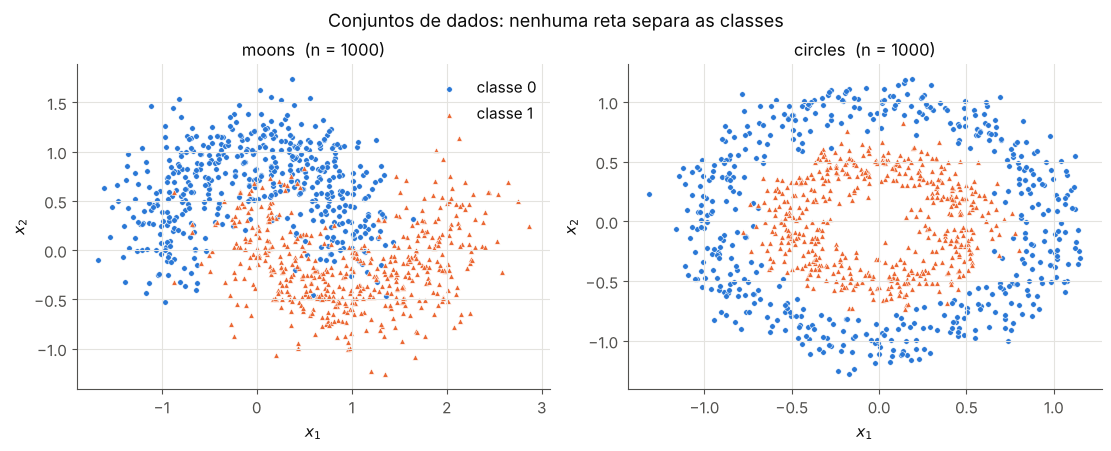

In [ ]:
N = 1000
X_moons, y_moons = make_moons(n_samples=N, noise=0.30, random_state=SEED)
X_circ, y_circ = make_circles(n_samples=N, noise=0.12, factor=0.5, random_state=SEED)

BRUTOS = {"moons": (X_moons, y_moons), "circles": (X_circ, y_circ)}
DADOS = {nome: dividir(X, y) for nome, (X, y) in BRUTOS.items()}   # (X_tr, X_va, X_te, y_tr, y_va, y_te)
DEV = {nome: (np.vstack([d[0], d[1]]), np.concatenate([d[3], d[4]])) for nome, d in DADOS.items()}   # treino + validação

display(pd.DataFrame([{"conjunto": nome, "treino": len(d[3]), "validação": len(d[4]), "teste": len(d[5]),
                       "% classe 1 no treino": 100 * d[3].mean(), "% classe 1 no teste": 100 * d[5].mean()}
                      for nome, d in DADOS.items()]).set_index("conjunto"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
for ax, (nome, (X, y)) in zip(axes, BRUTOS.items()):
    for c in (0, 1):
        ax.scatter(X[y == c, 0], X[y == c, 1], s=16, c=CORES_CLASSE[c], marker=MARCADORES[c],
                   edgecolors="white", linewidths=0.4, label=f"classe {c}")
    ax.set_title(f"{nome}  (n = {len(y)})"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
axes[0].legend(loc="upper right")
fig.suptitle("Conjuntos de dados: nenhuma reta separa as classes")
plt.show()

## `Experimento 1: Kernels linear, polinomial e RBF`

Para a comparação ser justa, cada kernel recebe uma **pequena busca de hiperparâmetros**, escolhida pela acurácia média na **validação cruzada (5 partes) sobre treino + validação**:

- **linear:** $C\in\{0{,}01;\ 0{,}1;\ 1;\ 10;\ 100\}$
- **polinomial:** grau $d\in\{2,3,4,5\}$, $r\in\{0,1\}$, $C\in\{0{,}1;\ 1;\ 10;\ 100\}$ ($\gamma$ = `"scale"`)
- **RBF:** $C\in\{0{,}1;\ 1;\ 10;\ 100\}$, $\gamma\in\{0{,}1;\ 0{,}5;\ 1;\ 2;\ 5;\ 10\}$

In [ ]:
GRADES_KERNEL = {
    "Linear":     {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    "Polinomial": {"svc__kernel": ["poly"], "svc__degree": [2, 3, 4, 5], "svc__coef0": [0, 1],
                   "svc__C": [0.1, 1, 10, 100]},                               # γ do polinomial = "scale"
    "RBF":        {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.1, 0.5, 1, 2, 5, 10]},
}

def sem_prefixo(p):
    return {k.replace("svc__", ""): v for k, v in p.items()}

def descrever(p):
    """Texto curto com os hiperparâmetros relevantes."""
    p = sem_prefixo(p)
    s = f"C={p['C']:g}"
    if p["kernel"] == "poly":
        s += f", d={p['degree']}, r={p['coef0']}"
    if p["kernel"] == "rbf":
        s += f", γ={p['gamma']:g}"
    return s

linhas_k, modelos_k = [], {}
for nome_dados, (X_dev, y_dev) in DEV.items():
    for nome_k, grade in GRADES_KERNEL.items():
        busca = GridSearchCV(svm(), grade, cv=CV, scoring="accuracy", n_jobs=-1, return_train_score=True)
        busca.fit(X_dev, y_dev)
        i, m = busca.best_index_, busca.best_estimator_            # best_estimator_ já foi reajustado nos 800 pontos
        r = {"acc_treino": busca.cv_results_["mean_train_score"][i], "acc_vc": busca.best_score_,
             "desvio_vc": busca.cv_results_["std_test_score"][i], "n_vs": int(m[-1].n_support_.sum()),
             "t_treino_ms": tempo_mediano(svm(**sem_prefixo(busca.best_params_)), X_dev, y_dev)}
        r["pct_vs"] = 100 * r["n_vs"] / len(y_dev)
        modelos_k[(nome_dados, nome_k)] = (m, busca.best_params_, r)
        linhas_k.append({"conjunto": nome_dados, "kernel": nome_k,
                         "melhores hiperparâmetros": descrever(busca.best_params_), **r})

tab_k = pd.DataFrame(linhas_k).set_index(["conjunto", "kernel"])
display(tab_k[["melhores hiperparâmetros", "acc_treino", "acc_vc", "desvio_vc", "n_vs", "pct_vs", "t_treino_ms"]]
        .rename(columns={"acc_treino": "acurácia treino", "acc_vc": "acurácia VC", "desvio_vc": "desvio VC",
                         "n_vs": "nº VS", "pct_vs": "% VS", "t_treino_ms": "treino (ms)"})
        .style.format({"acurácia treino": "{:.3f}", "acurácia VC": "{:.3f}", "desvio VC": "{:.3f}",
                       "% VS": "{:.1f}", "treino (ms)": "{:.1f}"}))

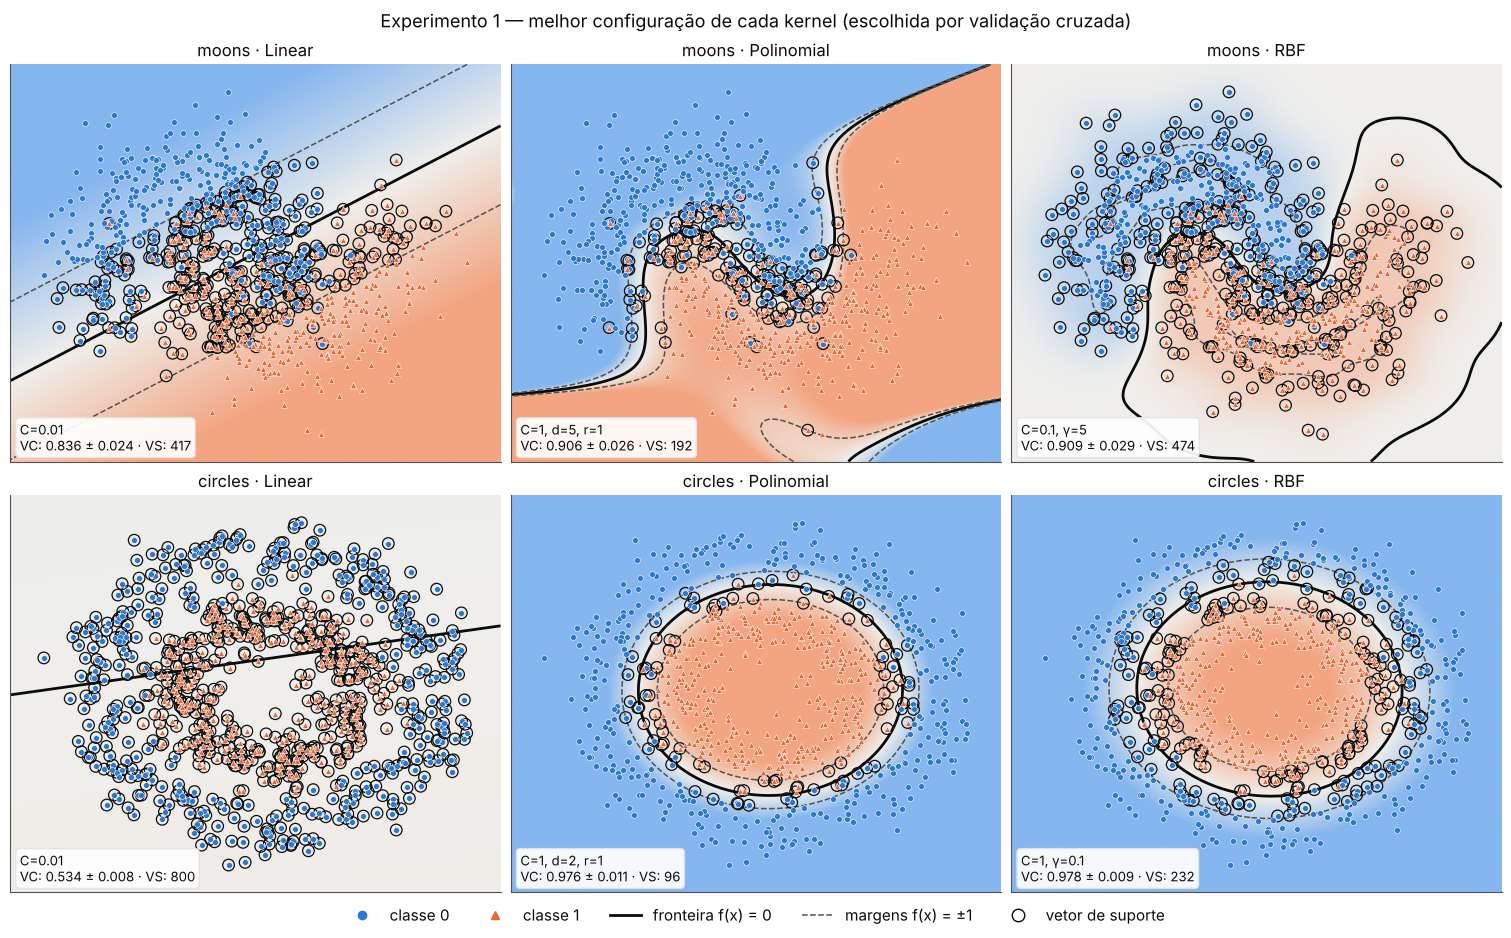

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.3), layout="constrained")
for i, (nome_dados, (X_dev, y_dev)) in enumerate(DEV.items()):
    for j, nome_k in enumerate(GRADES_KERNEL):
        m, p, r = modelos_k[(nome_dados, nome_k)]
        plot_fronteira(m, X_dev, y_dev, axes[i, j], titulo=f"{nome_dados} · {nome_k}",
                       vs=vetores_suporte(m, X_dev),
                       info=f"{descrever(p)}\nVC: {r['acc_vc']:.3f} ± {r['desvio_vc']:.3f} · VS: {r['n_vs']}")
legenda_fronteira(fig)
fig.suptitle("Experimento 1 — melhor configuração de cada kernel (escolhida por validação cruzada)")
plt.show()


**Leitura dos resultados (Exp. 1)**

- **Kernel linear:** apresentou desempenho inferior nos dois conjuntos, especialmente no *circles*, com acurácia de validação cruzada de 0,53 (próxima ao acaso). No *moons*, alcançou aproximadamente 0,84, mostrando dificuldade para representar fronteiras não lineares.

- **Kernels polinomial e RBF:** tiveram desempenhos semelhantes. No *moons*, alcançaram 0,906 e 0,909, respectivamente; no *circles*, 0,976 e 0,978. As diferenças foram pequenas em relação à variação da validação cruzada.

- **Diferença entre os kernels:** o polinomial pode produzir decisões mais extremas longe dos dados, enquanto a RBF utiliza influências locais dos vetores de suporte. Mesmo longe dos dados, a RBF continua produzindo uma classificação.

- **Conclusão:** os kernels não lineares foram mais adequados aos conjuntos analisados. A RBF apresentou bom desempenho nos dois problemas, com a vantagem de não exigir a escolha de um grau polinomial, sendo sua flexibilidade controlada principalmente por $C$ e $\gamma$.


## `Experimento 2:` $C$ fixo ($C=1$), variando $\gamma$

Mantemos $C=1$ e variamos $\gamma$ em cinco ordens de grandeza no conjunto **moons**. Como os dados estão padronizados, $\gamma=1$ corresponde a gaussianas com desvio $\sigma = 1/\sqrt{2}\approx 0{,}7$ desvio-padrão dos atributos.

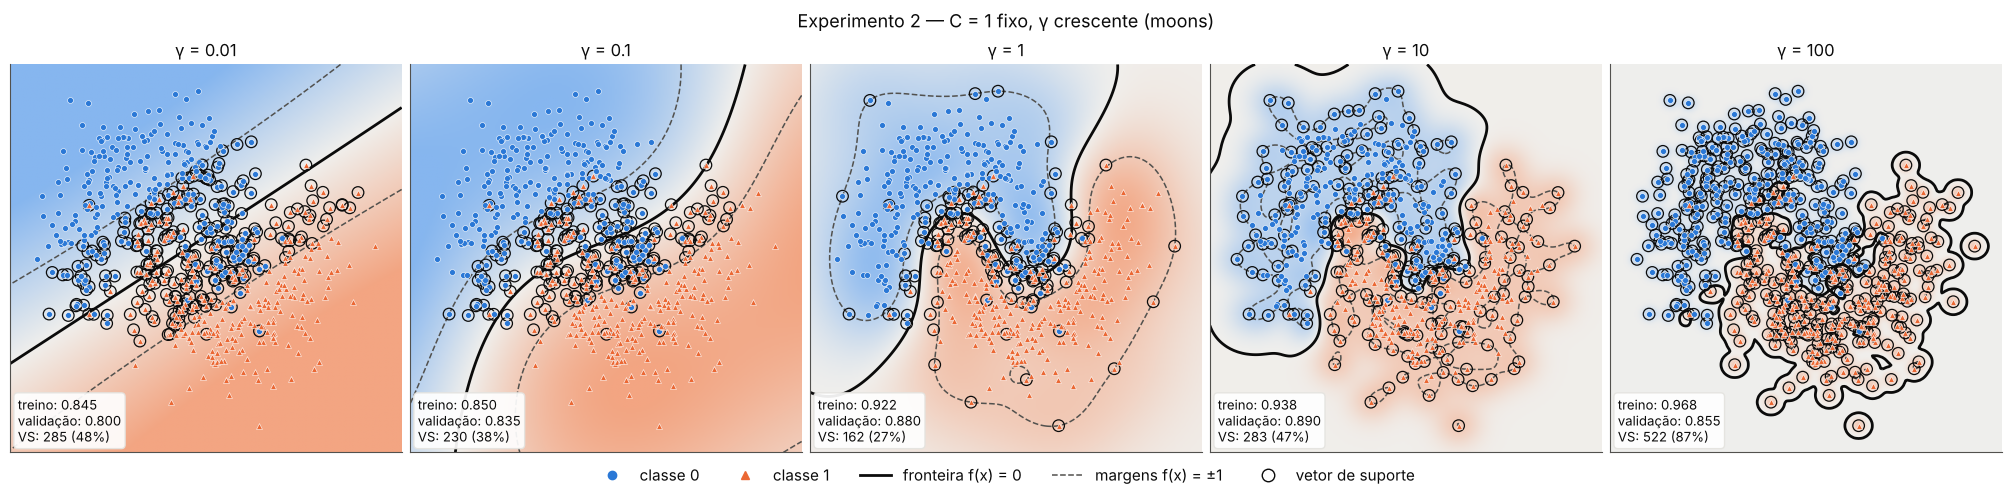

In [ ]:
X_tr, X_va, X_te, y_tr, y_va, y_te = DADOS["moons"]
C_FIXO = 1.0
GAMMAS_PAINEL = [0.01, 0.1, 1, 10, 100]

fig, axes = plt.subplots(1, len(GAMMAS_PAINEL), figsize=(20, 4.9), layout="constrained")
for ax, g in zip(axes, GAMMAS_PAINEL):
    m = svm(kernel="rbf", C=C_FIXO, gamma=g)
    r = treinar_avaliar(m, X_tr, y_tr, X_va, y_va)
    plot_fronteira(m, X_tr, y_tr, ax, titulo=f"γ = {g:g}", vs=vetores_suporte(m, X_tr),
                   info=f"treino: {r['acc_treino']:.3f}\nvalidação: {r['acc_val']:.3f}\nVS: {r['n_vs']} ({r['pct_vs']:.0f}%)")
legenda_fronteira(fig)
fig.suptitle(f"Experimento 2 — C = {C_FIXO:g} fixo, γ crescente (moons)")
plt.show()

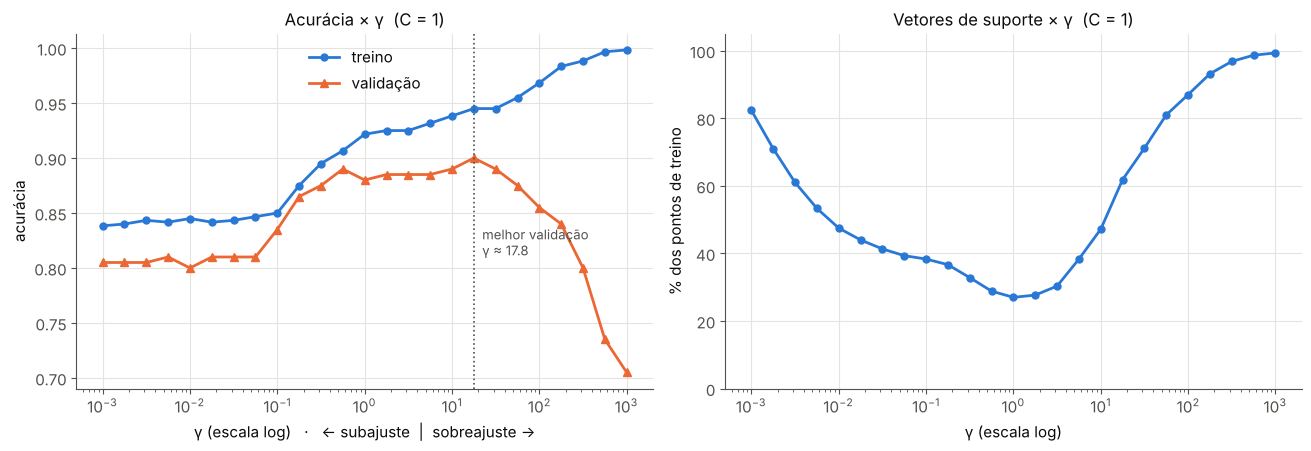

Melhor γ na validação (C=1): 17.8 → acurácia de validação 0.900
No maior γ (1000): treino 0.998 × validação 0.705  → diferença de 0.293


In [ ]:
# curva de validação: γ em escala logarítmica, de 0,001 a 1000
gammas = np.logspace(-3, 3, 25)
curva_g = pd.DataFrame([{"gamma": g, **treinar_avaliar(svm(kernel="rbf", C=C_FIXO, gamma=g), X_tr, y_tr, X_va, y_va)}
                        for g in gammas])
g_best = curva_g.loc[curva_g["acc_val"].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
ax = axes[0]
ax.plot(curva_g["gamma"], curva_g["acc_treino"], "o-", color=AZUL, ms=5, label="treino")
ax.plot(curva_g["gamma"], curva_g["acc_val"], "^-", color=LARANJA, ms=6, label="validação")
ax.axvline(g_best["gamma"], color=TINTA_2, ls=":", lw=1.2)
ax.annotate(f"melhor validação\nγ ≈ {g_best['gamma']:.3g}", (g_best["gamma"], g_best["acc_val"]),
            xytext=(6, -70), textcoords="offset points", fontsize=9.5, color=TINTA_2)
ax.set(xscale="log", xlabel="γ (escala log)   ·   ← subajuste  |  sobreajuste →", ylabel="acurácia",
       title="Acurácia × γ  (C = 1)")
ax.legend(loc="upper center")
ax = axes[1]
ax.plot(curva_g["gamma"], curva_g["pct_vs"], "o-", color=AZUL, ms=5)
ax.set(xscale="log", xlabel="γ (escala log)", ylabel="% dos pontos de treino", title="Vetores de suporte × γ  (C = 1)", ylim=(0, 105))
plt.show()

print(f"Melhor γ na validação (C=1): {g_best['gamma']:.3g} → acurácia de validação {g_best['acc_val']:.3f}")
i_max = curva_g["gamma"].idxmax()
print(f"No maior γ ({curva_g.loc[i_max, 'gamma']:g}): treino {curva_g.loc[i_max, 'acc_treino']:.3f} × "
      f"validação {curva_g.loc[i_max, 'acc_val']:.3f}  → diferença de {curva_g.loc[i_max, 'acc_treino'] - curva_g.loc[i_max, 'acc_val']:.3f}")


**Leitura dos resultados (Exp. 2)**

- **$\gamma$ pequeno - subajuste:** com $\gamma=0,01$, a fronteira ficou quase linear, com acurácia de treino de 0,845 e validação de 0,800. O modelo não conseguiu acompanhar bem o formato das meias-luas.

- **$\gamma$ intermediário - melhor desempenho:** a fronteira acompanhou melhor os dados, alcançando **0,900 de acurácia de validação** em $\gamma\approx 18$, com $C=1$.

- **$\gamma$ grande - sobreajuste:** a fronteira ficou muito complexa, criando pequenas "ilhas" ao redor dos pontos. Com $\gamma=1000$, o treino chegou a 0,998, mas a validação caiu para 0,705.

- **Vetores de suporte:** a quantidade de VS foi menor para valores intermediários de $\gamma$ (≈ 27%) e aumentou nos extremos, chegando a 99% em $\gamma=1000$.

- **Conclusão:** $\gamma$ controla o **alcance da influência de cada exemplo** e, consequentemente, a flexibilidade da fronteira. Valores intermediários apresentaram o melhor equilíbrio entre ajuste e generalização.


##`Experimento 3:` $\gamma$ fixo ($\gamma=1$), variando $C$

Agora mantemos $\gamma=1$ e variamos $C$. Além das acurácias, medimos três quantidades ligadas diretamente à margem suave:

- **largura da margem** $2/\|\mathbf w\|$ no espaço de características, com $\|\mathbf w\|^2=\sum_{i,j}\alpha_i\alpha_j y_i y_j K(\mathbf x_i,\mathbf x_j)$ (o sklearn guarda $\alpha_i y_i$ em `dual_coef_`);
- **violações da margem:** pontos de treino com $y_i f(\mathbf x_i)<1$ (dentro da faixa tracejada ou do lado errado);
- **erros de treino:** pontos com $y_i f(\mathbf x_i)<0$ (do lado errado da fronteira).

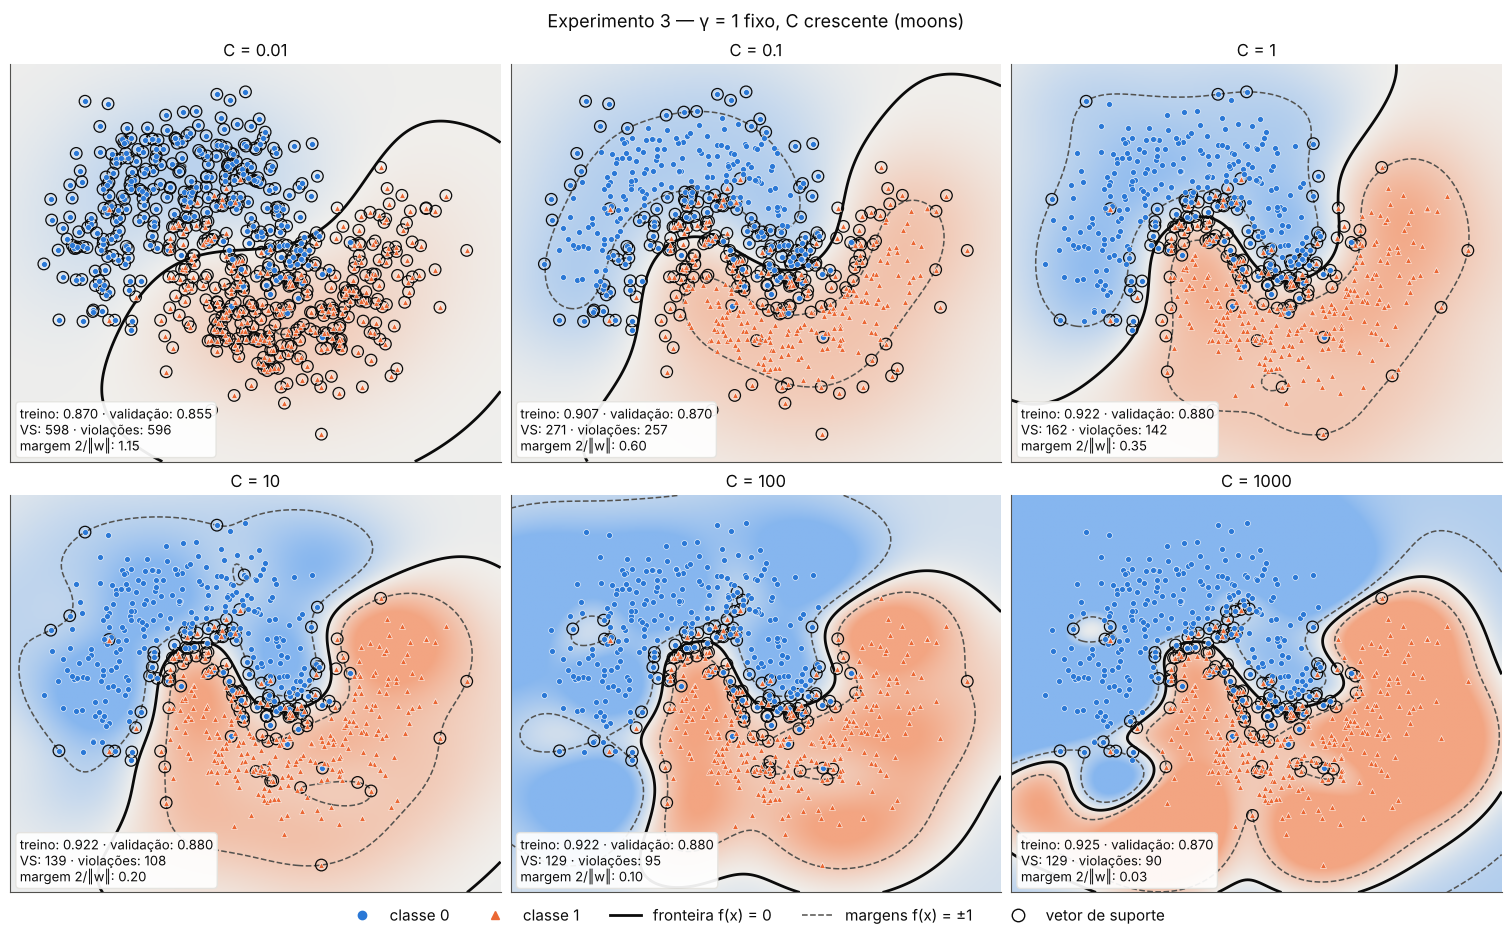

In [ ]:
G_FIXO = 1.0
CS_PAINEL = [0.01, 0.1, 1, 10, 100, 1000]

fig, axes = plt.subplots(2, 3, figsize=(15, 9.3), layout="constrained")
for ax, c in zip(axes.ravel(), CS_PAINEL):
    m = svm(kernel="rbf", C=c, gamma=G_FIXO)
    r = treinar_avaliar(m, X_tr, y_tr, X_va, y_va)
    mv = margem_e_violacoes(m, X_tr, y_tr)
    plot_fronteira(m, X_tr, y_tr, ax, titulo=f"C = {c:g}", vs=vetores_suporte(m, X_tr),
                   info=(f"treino: {r['acc_treino']:.3f} · validação: {r['acc_val']:.3f}\n"
                         f"VS: {r['n_vs']} · violações: {mv['violacoes']}\nmargem 2/‖w‖: {mv['margem']:.2f}"))
legenda_fronteira(fig)
fig.suptitle(f"Experimento 3 — γ = {G_FIXO:g} fixo, C crescente (moons)")
plt.show()

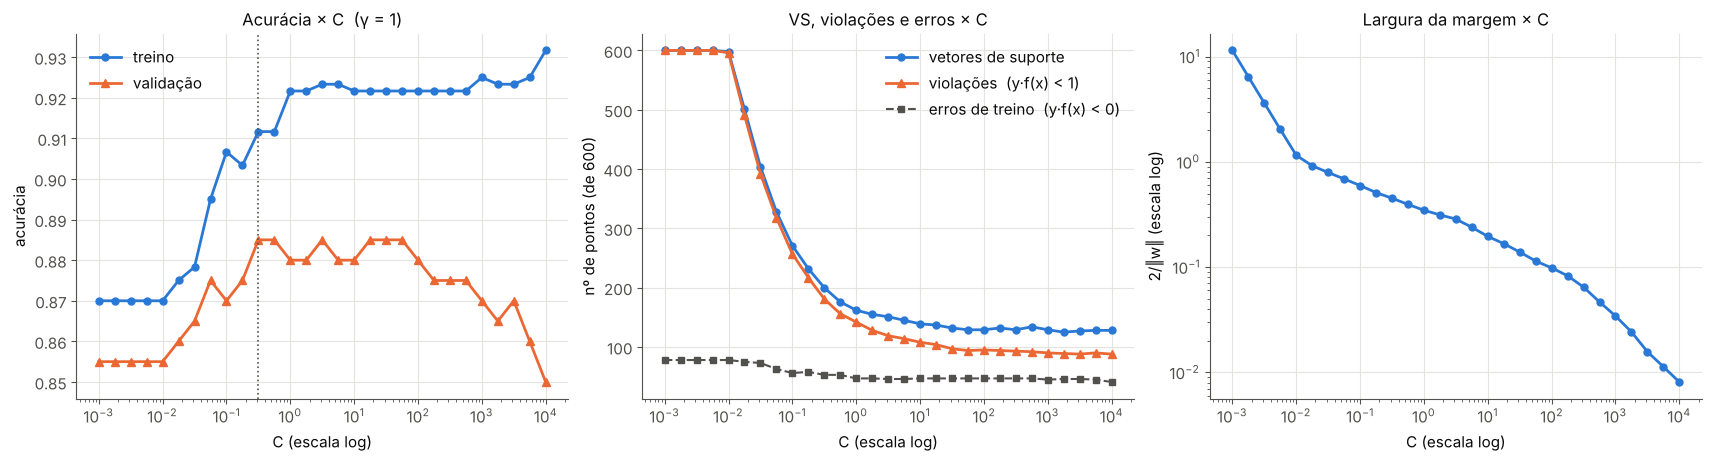

Melhor C na validação (γ=1): 0.316 → acurácia de validação 0.885
C =    0.001: margem  11.437 · VS 600 · violações 600 · erros de treino  78 · treino 0.870 · validação 0.855
C =        1: margem   0.347 · VS 162 · violações 142 · erros de treino  47 · treino 0.922 · validação 0.880
C =    1e+04: margem   0.008 · VS 128 · violações  88 · erros de treino  41 · treino 0.932 · validação 0.850


In [ ]:
Cs = np.logspace(-3, 4, 29)
linhas_c = []
for c in Cs:
    m = svm(kernel="rbf", C=c, gamma=G_FIXO)
    linhas_c.append({"C": c, **treinar_avaliar(m, X_tr, y_tr, X_va, y_va), **margem_e_violacoes(m, X_tr, y_tr)})
curva_c = pd.DataFrame(linhas_c)
c_best = curva_c.loc[curva_c["acc_val"].idxmax()]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")
ax = axes[0]
ax.plot(curva_c["C"], curva_c["acc_treino"], "o-", color=AZUL, ms=5, label="treino")
ax.plot(curva_c["C"], curva_c["acc_val"], "^-", color=LARANJA, ms=6, label="validação")
ax.axvline(c_best["C"], color=TINTA_2, ls=":", lw=1.2)
ax.set(xscale="log", xlabel="C (escala log)", ylabel="acurácia", title="Acurácia × C  (γ = 1)")
ax.legend(loc="upper left")
ax = axes[1]
ax.plot(curva_c["C"], curva_c["n_vs"], "o-", color=AZUL, ms=5, label="vetores de suporte")
ax.plot(curva_c["C"], curva_c["violacoes"], "^-", color=LARANJA, ms=6, label="violações  (y·f(x) < 1)")
ax.plot(curva_c["C"], curva_c["erros_treino"], "s--", color=TINTA_2, ms=5, lw=1.5, label="erros de treino  (y·f(x) < 0)")
ax.set(xscale="log", xlabel="C (escala log)", ylabel=f"nº de pontos (de {len(y_tr)})", title="VS, violações e erros × C")
ax.legend(loc="upper right")
ax = axes[2]
ax.plot(curva_c["C"], curva_c["margem"], "o-", color=AZUL, ms=5)
ax.set(xscale="log", yscale="log", xlabel="C (escala log)", ylabel="2/‖w‖ (escala log)", title="Largura da margem × C")
plt.show()

print(f"Melhor C na validação (γ=1): {c_best['C']:.3g} → acurácia de validação {c_best['acc_val']:.3f}")
for c in (Cs[0], 1.0, Cs[-1]):
    lin = curva_c.iloc[(curva_c["C"] - c).abs().argmin()]
    print(f"C = {lin['C']:>8.3g}: margem {lin['margem']:7.3f} · VS {lin['n_vs']:3.0f} · violações {lin['violacoes']:3.0f} · "
          f"erros de treino {lin['erros_treino']:3.0f} · treino {lin['acc_treino']:.3f} · validação {lin['acc_val']:.3f}")


**Leitura dos resultados (Exp. 3)**

- **$C$ pequeno:** produz margens mais largas e aceita mais violações. Com $C=0,01$, quase todos os pontos se tornaram vetores de suporte (598 de 600), indicando uma regularização muito forte.

- **Aumento de $C$:** a margem diminuiu aproximadamente 1.400 vezes, enquanto as violações caíram de 600 para 88. O modelo passou a penalizar mais os erros de treinamento.

- **Desempenho:** a acurácia de validação aumentou até $C\approx 0,3$ (0,885), manteve-se estável por um intervalo e depois caiu para 0,850 em $C=10^4$, indicando início de sobreajuste.

- **Interação com $\gamma$:** com $\gamma=1$, o efeito de $C$ foi mais moderado, pois ele controla a penalização dos erros, enquanto $\gamma$ determina o alcance das gaussianas.

- **Conclusão:** valores muito pequenos de $C$ podem causar subajuste, enquanto valores muito grandes aumentam o risco de sobreajuste. O ideal é buscar um equilíbrio entre margem e desempenho de validação.


## `Experimento 4:` Interação $C\times\gamma$ e seleção de hiperparâmetros

Os experimentos 2 e 3 variam um parâmetro de cada vez. Aqui varremos a **grade completa**: 13 valores de $C$ ($10^{-2}$ a $10^{4}$) × 13 valores de $\gamma$ ($10^{-3}$ a $10^{3}$), meia década entre valores.

**Procedimento de seleção:** `GridSearchCV` com **validação cruzada estratificada de 5 partes** sobre treino + validação (800 pontos). A combinação com maior acurácia média de validação cruzada é a escolhida. A validação cruzada é mais estável que uma única partição de validação de 200 pontos. O teste continua intocado.

In [ ]:
GRADE_CG = {"svc__C": np.logspace(-2, 4, 13), "svc__gamma": np.logspace(-3, 3, 13)}

def selecionar(X_dev, y_dev):
    busca = GridSearchCV(svm(kernel="rbf"), GRADE_CG, cv=CV, scoring="accuracy",
                         n_jobs=-1, return_train_score=True)
    t0 = time.perf_counter(); busca.fit(X_dev, y_dev); dt = time.perf_counter() - t0
    res = pd.DataFrame(busca.cv_results_)
    res["C"] = res["param_svc__C"].astype(float)
    res["gamma"] = res["param_svc__gamma"].astype(float)
    return busca, res, dt

X_dev, y_dev = DEV["moons"]
busca_moons, res_moons, dt = selecionar(X_dev, y_dev)
print(f"{len(res_moons)} combinações × 5 partes = {5 * len(res_moons)} ajustes em {dt:.1f} s")
print(f"Melhor combinação (moons): C = {busca_moons.best_params_['svc__C']:.3g}, "
      f"γ = {busca_moons.best_params_['svc__gamma']:.3g} → acurácia média na validação cruzada = {busca_moons.best_score_:.3f}")

# nº de vetores de suporte de cada combinação (modelo ajustado em treino + validação)
res_moons["pct_vs"] = [100 * svm(kernel="rbf", C=c, gamma=g).fit(X_dev, y_dev)[-1].n_support_.sum() / len(y_dev)
                       for c, g in zip(res_moons["C"], res_moons["gamma"])]

169 combinações × 5 partes = 845 ajustes em 19.9 s
Melhor combinação (moons): C = 0.316, γ = 3.16 → acurácia média na validação cruzada = 0.912


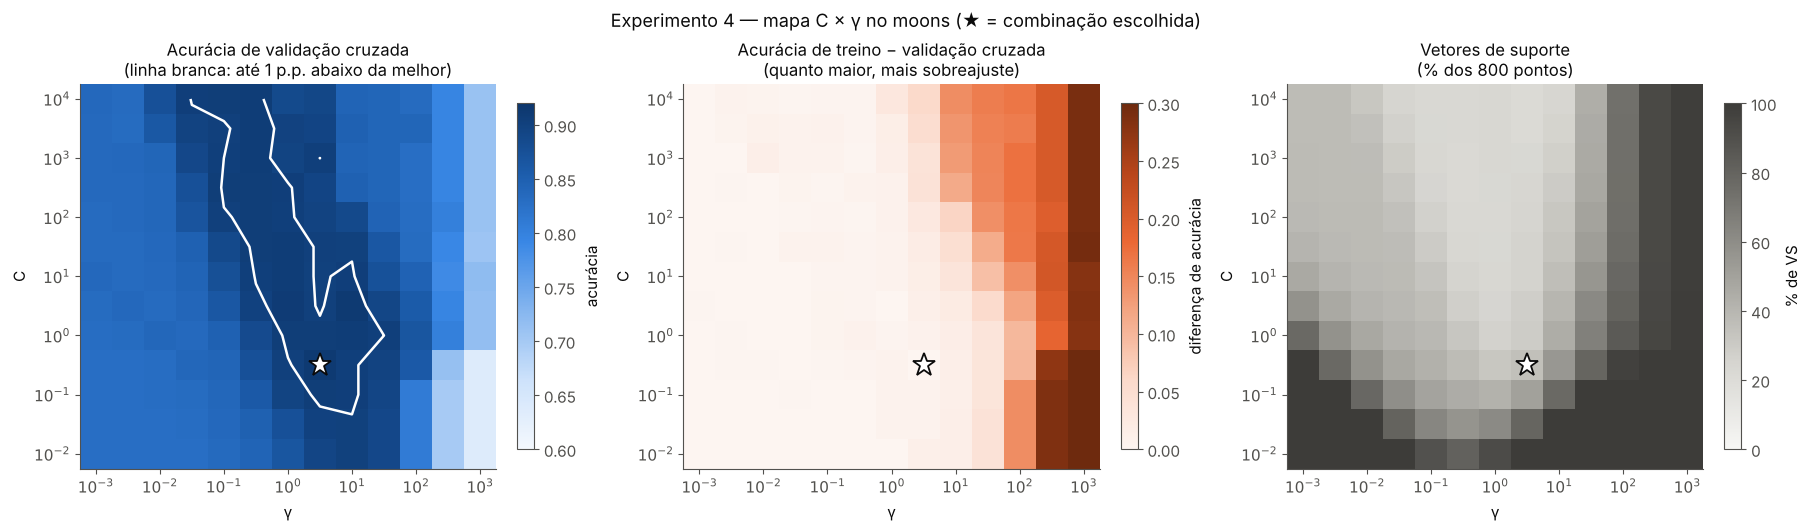

In [ ]:
def mapa(ax, res, coluna, titulo, cmap, vmin, vmax, rotulo, marcar=None):
    M = res.pivot(index="C", columns="gamma", values=coluna)
    im = ax.imshow(M.values, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    g_vals, c_vals = M.columns.values, M.index.values
    ax.set_xticks(range(0, len(g_vals), 2)); ax.set_xticklabels([f"$10^{{{np.log10(v):.0f}}}$" for v in g_vals[::2]])
    ax.set_yticks(range(0, len(c_vals), 2)); ax.set_yticklabels([f"$10^{{{np.log10(v):.0f}}}$" for v in c_vals[::2]])
    ax.set(xlabel="γ", ylabel="C", title=titulo); ax.grid(False)
    if marcar is not None:
        j = int(np.argmin(np.abs(g_vals - marcar[1]))); i = int(np.argmin(np.abs(c_vals - marcar[0])))
        ax.plot(j, i, marker="*", ms=17, mfc="white", mec=TINTA, mew=1.3)
    plt.colorbar(im, ax=ax, label=rotulo, shrink=0.9)
    return M

melhor = (busca_moons.best_params_["svc__C"], busca_moons.best_params_["svc__gamma"])
res_moons["gap"] = res_moons["mean_train_score"] - res_moons["mean_test_score"]   # sinal de sobreajuste
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), layout="constrained")
M = mapa(axes[0], res_moons, "mean_test_score", "Acurácia de validação cruzada\n(linha branca: até 1 p.p. abaixo da melhor)",
         CMAP_AZUL, 0.6, 0.92, "acurácia", melhor)
axes[0].contour(M.values, levels=[busca_moons.best_score_ - 0.01], colors="white", linewidths=1.8)
mapa(axes[1], res_moons, "gap", "Acurácia de treino − validação cruzada\n(quanto maior, mais sobreajuste)",
     CMAP_LARANJA, 0, 0.3, "diferença de acurácia", melhor)
mapa(axes[2], res_moons, "pct_vs", "Vetores de suporte\n(% dos 800 pontos)", CMAP_CINZA, 0, 100, "% de VS", melhor)
fig.suptitle("Experimento 4 — mapa C × γ no moons (★ = combinação escolhida)")
plt.show()

In [ ]:
# as 10 melhores combinações: várias regiões da grade chegam a desempenhos parecidos
top = (res_moons.sort_values("mean_test_score", ascending=False).head(10)
       [["C", "gamma", "mean_test_score", "std_test_score", "mean_train_score", "pct_vs"]]
       .rename(columns={"gamma": "γ", "mean_test_score": "acc VC (média)", "std_test_score": "acc VC (desvio)",
                        "mean_train_score": "acc treino", "pct_vs": "% VS"}))
display(top.style.format({"C": "{:.3g}", "γ": "{:.3g}", "acc VC (média)": "{:.3f}", "acc VC (desvio)": "{:.3f}",
                          "acc treino": "{:.3f}", "% VS": "{:.1f}"}).hide(axis="index"))

C,γ,acc VC (média),acc VC (desvio),acc treino,% VS
0.316,3.16,0.912,0.026,0.912,35.5
3.16,10,0.911,0.025,0.932,40.1
3.16,1,0.910,0.026,0.909,24.5
1e+03,0.316,0.907,0.027,0.910,22.2
10,1,0.907,0.029,0.912,23.2
1,10,0.907,0.027,0.923,44.5
3.16e+03,0.316,0.907,0.029,0.911,22.5
31.6,1,0.907,0.029,0.912,23.0
1e+04,0.316,0.907,0.029,0.910,22.4
1e+04,0.1,0.906,0.031,0.909,22.5


Para ver a interação **na fronteira**, a galeria abaixo cruza três valores de $C$ (linhas) com três de $\gamma$ (colunas). Modelos treinados no conjunto de treino; acurácia medida na validação.

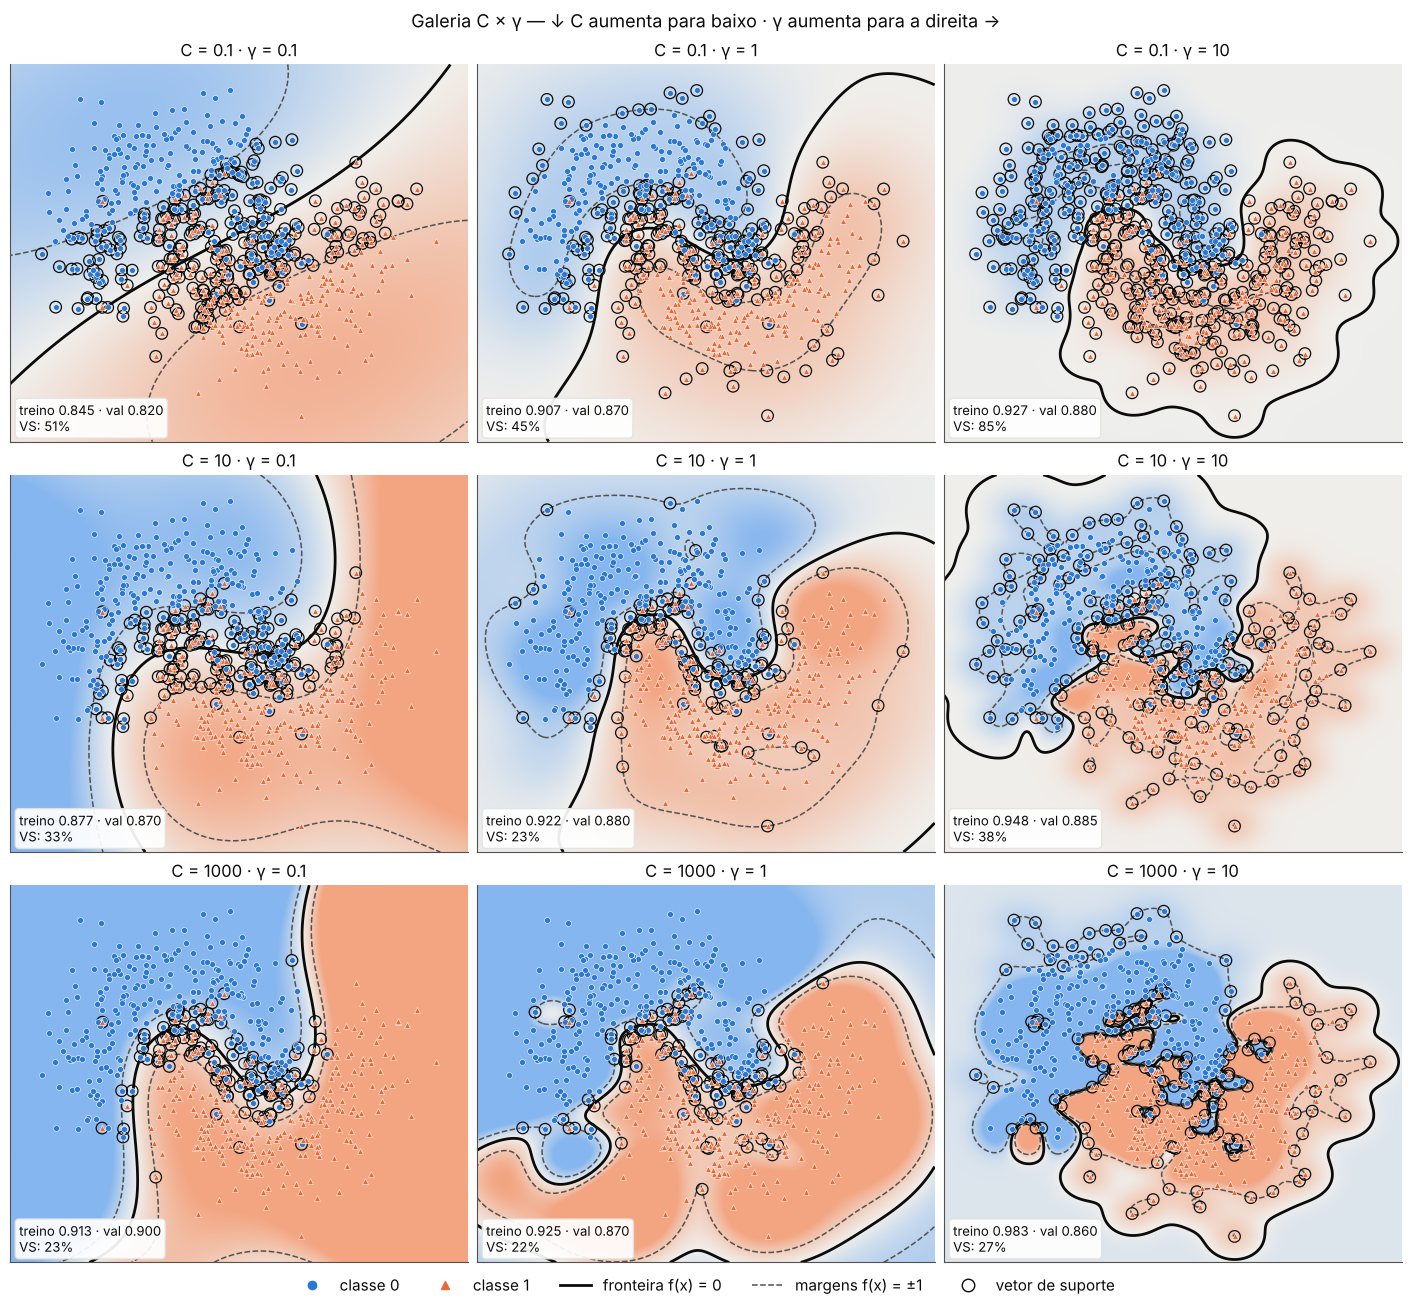

In [ ]:
X_tr, X_va, X_te, y_tr, y_va, y_te = DADOS["moons"]
CS_GAL, GS_GAL = [0.1, 10, 1000], [0.1, 1, 10]
fig, axes = plt.subplots(3, 3, figsize=(14, 13), layout="constrained")
for i, c in enumerate(CS_GAL):
    for j, g in enumerate(GS_GAL):
        m = svm(kernel="rbf", C=c, gamma=g)
        r = treinar_avaliar(m, X_tr, y_tr, X_va, y_va)
        plot_fronteira(m, X_tr, y_tr, axes[i, j], titulo=f"C = {c:g} · γ = {g:g}", vs=vetores_suporte(m, X_tr),
                       info=f"treino {r['acc_treino']:.3f} · val {r['acc_val']:.3f}\nVS: {r['pct_vs']:.0f}%")
legenda_fronteira(fig)
fig.suptitle("Galeria C × γ — ↓ C aumenta para baixo · γ aumenta para a direita →")
plt.show()


**Leitura dos resultados (Exp. 4)**

- **Melhores combinações:** o mapa mostrou uma faixa diagonal de bom desempenho, com acurácias entre 0,906 e 0,912. As diferenças foram pequenas em relação ao desvio da validação cruzada (≈ 0,03).

- **Interação entre $C$ e $\gamma$:** valores menores de $\gamma$ podem ser compensados por valores maiores de $C$, e vice-versa. Isso acontece porque os dois parâmetros influenciam a flexibilidade e a regularização da fronteira.

- **Valores extremos:** com $\gamma$ muito pequeno (0,001), houve subajuste (validação ≈ 0,83). Com $\gamma$ muito grande (1000), houve sobreajuste (validação ≤ 0,72). Nesses casos, variar $C$ não resolveu o problema.

- **Vetores de suporte:** a quantidade de VS foi menor nas regiões de bom desempenho e maior nas combinações extremas.

- **Melhor combinação encontrada:** $C\approx 0,32$ e $\gamma\approx 3,2$, com acurácia de validação cruzada de **0,912 ± 0,026**.

- **Conclusão:** não existe um melhor $C$ ou $\gamma$ isoladamente. Os dois devem ser **ajustados em conjunto**, utilizando busca em grade e validação cruzada.


## `Experimento 5: A importância da padronização`

**7a. Visualização em 2D.** Pegamos o *moons* e multiplicamos $x_1$ por 100, como se um atributo estivesse em centímetros e o outro em metros. A informação é exatamente a mesma; só mudou a unidade. Comparamos três modelos ($C=1$):

1. **sem padronização, $\gamma=1$** , o mesmo $\gamma$ que funcionava bem nos dados padronizados;
2. **sem padronização, `gamma="scale"`** , o padrão do sklearn, $\gamma = 1/(n_{\text{atrib}}\cdot \mathrm{Var}(X))$, que usa **uma única variância para todos os atributos**;
3. **com padronização, $\gamma=1$.**

Desvio-padrão de cada atributo no treino: x1 = 92.3 · x2 = 0.56


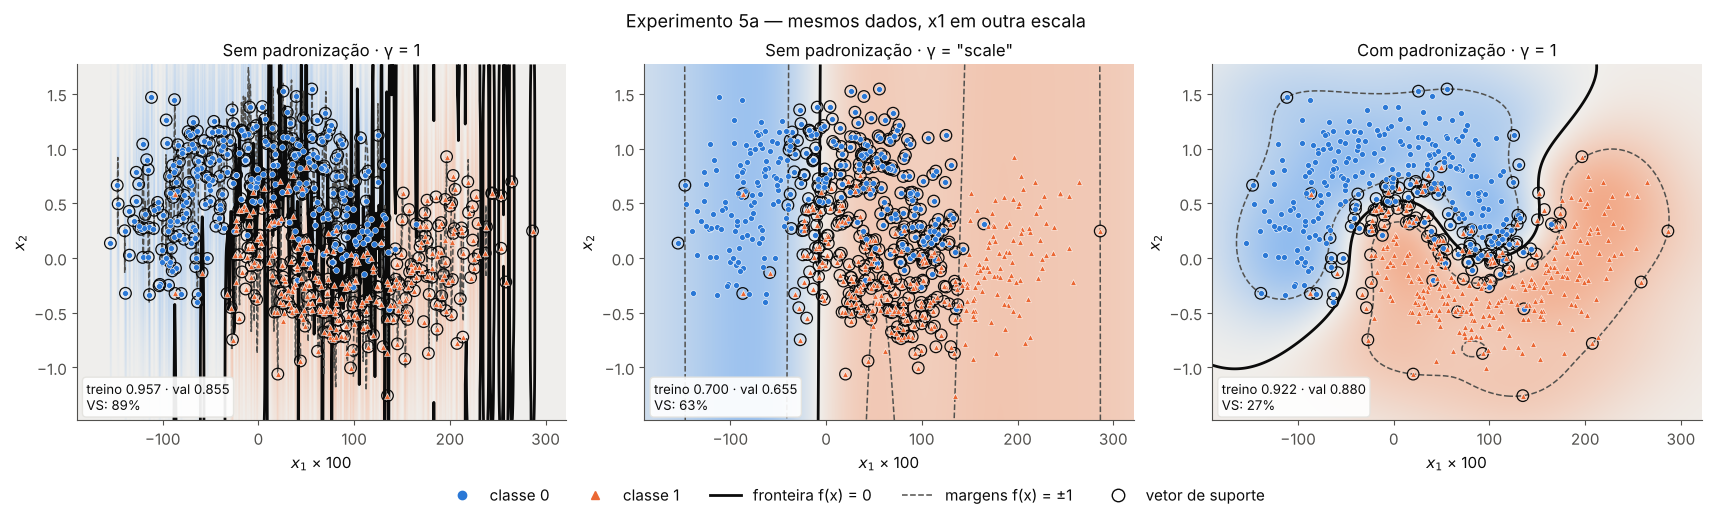

,γ efetivo,acurácia treino,acurácia validação,% VS
modelo,,,,
Sem padronização · γ = 1,1.00e+00,0.957,0.855,88.7
"Sem padronização · γ = ""scale""",1.03e-04,0.700,0.655,62.7
Com padronização · γ = 1,1.00e+00,0.922,0.880,27.0


In [ ]:
X_esc = X_moons.copy()
X_esc[:, 0] *= 100                                           # x1 agora vai de ~ -150 a ~ 250
Xe_tr, Xe_va, Xe_te, ye_tr, ye_va, ye_te = dividir(X_esc, y_moons)
print(f"Desvio-padrão de cada atributo no treino: x1 = {Xe_tr[:, 0].std():.1f} · x2 = {Xe_tr[:, 1].std():.2f}")

casos = {"Sem padronização · γ = 1": svm(padronizar=False, kernel="rbf", C=1, gamma=1),
         'Sem padronização · γ = "scale"': svm(padronizar=False, kernel="rbf", C=1, gamma="scale"),
         "Com padronização · γ = 1": svm(padronizar=True, kernel="rbf", C=1, gamma=1)}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.1), layout="constrained")
linhas_p = []
for ax, (nome, m) in zip(axes, casos.items()):
    r = treinar_avaliar(m, Xe_tr, ye_tr, Xe_va, ye_va)
    g_efetivo = m[-1]._gamma
    linhas_p.append({"modelo": nome, "γ efetivo": g_efetivo, **r})
    plot_fronteira(m, Xe_tr, ye_tr, ax, titulo=nome, vs=vetores_suporte(m, Xe_tr), eixos=True, res=500,
                   info=f"treino {r['acc_treino']:.3f} · val {r['acc_val']:.3f}\nVS: {r['pct_vs']:.0f}%")
    ax.set_xlabel("$x_1$ × 100"); ax.set_ylabel("$x_2$")
legenda_fronteira(fig)
fig.suptitle("Experimento 5a — mesmos dados, x1 em outra escala")
plt.show()
display(pd.DataFrame(linhas_p).set_index("modelo")[["γ efetivo", "acc_treino", "acc_val", "pct_vs"]]
        .rename(columns={"acc_treino": "acurácia treino", "acc_val": "acurácia validação", "pct_vs": "% VS"})
        .style.format({"γ efetivo": "{:.2e}", "acurácia treino": "{:.3f}", "acurácia validação": "{:.3f}", "% VS": "{:.1f}"}))

**7b. Um conjunto real: Breast Cancer Wisconsin** (569 exemplos, 30 atributos, já incluído no sklearn). Os atributos têm escalas muito diferentes — alguns ficam abaixo de 0,01 e outros passam de 1000. Comparamos, com validação cruzada estratificada de 5 partes:

- configuração padrão (`C=1`, `gamma="scale"`) sem e com padronização
- **melhor configuração de cada lado**, escolhida por busca em grade aninhada na validação cruzada, para mostrar que, sem padronizar, o problema não é só “escolher um $\gamma$ melhor”

In [ ]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)
nomes_bc = load_breast_cancer().feature_names
desv = pd.Series(X_bc.std(axis=0), index=nomes_bc)
print(f"Desvio-padrão dos atributos: mínimo {desv.min():.4f} ({desv.idxmin()}) · máximo {desv.max():.1f} ({desv.idxmax()}) "
      f"→ razão de {desv.max() / desv.min():,.0f}×")

CV_BC = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grade_cru = {"svc__C": np.logspace(-1, 4, 6), "svc__gamma": np.logspace(-8, 0, 9)}    # γ precisa ir bem baixo sem padronizar
grade_pad = {"svc__C": np.logspace(-1, 4, 6), "svc__gamma": np.logspace(-4, 1, 6)}
modelos_bc = {
    "sem padronização · C=1, γ='scale'": svm(padronizar=False, kernel="rbf"),
    "com padronização · C=1, γ='scale'": svm(padronizar=True, kernel="rbf"),
    "sem padronização · C e γ otimizados": GridSearchCV(svm(padronizar=False, kernel="rbf"), grade_cru, cv=3, n_jobs=-1),
    "com padronização · C e γ otimizados": GridSearchCV(svm(padronizar=True, kernel="rbf"), grade_pad, cv=3, n_jobs=-1),
}
linhas_bc = []
for nome, m in modelos_bc.items():
    cvr = cross_validate(m, X_bc, y_bc, cv=CV_BC, scoring=["accuracy", "f1"])
    linhas_bc.append({"modelo": nome, "acurácia (média)": cvr["test_accuracy"].mean(),
                      "acurácia (desvio)": cvr["test_accuracy"].std(), "F1 (média)": cvr["test_f1"].mean()})
tab_bc = pd.DataFrame(linhas_bc).set_index("modelo")
display(tab_bc.style.format("{:.3f}"))
print(f"Referência: classificar tudo como a classe majoritária dá acurácia {max(y_bc.mean(), 1 - y_bc.mean()):.3f}")

Desvio-padrão dos atributos: mínimo 0.0026 (fractal dimension error) · máximo 568.9 (worst area) → razão de 215,171×


,acurácia (média),acurácia (desvio),F1 (média)
modelo,,,
"sem padronização · C=1, γ='scale'",0.914,0.024,0.935
"com padronização · C=1, γ='scale'",0.977,0.016,0.982
sem padronização · C e γ otimizados,0.947,0.011,0.958
com padronização · C e γ otimizados,0.979,0.021,0.983


Referência: classificar tudo como a classe majoritária dá acurácia 0.627



**Leitura dos resultados (Exp. 5)**

- **7a. Dados sintéticos (*moons*):** ao multiplicar $x_1$ por 100, esse atributo passou a dominar as distâncias, prejudicando a classificação:
  - **Sem padronização ($\gamma=1$):** a fronteira ficou distorcida, com sobreajuste (treino 0,957 × validação 0,855).
  - **Sem padronização (`gamma="scale"`):** o ajuste automático de $\gamma$ não resolveu o problema, resultando em subajuste (validação 0,655).
  - **Com padronização:** a fronteira das meias-luas foi recuperada, com validação de 0,880.

- **7b. Dados reais (*Breast Cancer*):** os 30 atributos possuem escalas muito diferentes. Sem padronização, a acurácia foi de 0,914 e chegou a apenas 0,947 após otimização. Com padronização, alcançou **0,977 na configuração padrão e 0,979 após otimização**.

- **Conclusão:** a padronização é essencial nesses experimentos, pois impede que atributos de maior escala dominem as distâncias. Ela deve ser realizada dentro do `Pipeline`, evitando vazamento de informações durante a validação cruzada.


## `Tempo de treinamento e complexidade do modelo`

Dois aspectos de custo:

1. **Treino:** o SVC do sklearn (libsvm) resolve um problema de otimização quadrática cujo custo cresce entre $O(n^2)$ e $O(n^3)$ com o número de exemplos $n$; $C$ grande em dados com sobreposição também deixa a convergência mais lenta.
2. **Predição:** cada nova previsão calcula $K(\mathbf x_i,\mathbf x)$ para todos os vetores de suporte, então o custo de predição é proporcional ao nº de VS. O nº de VS é a medida natural de complexidade de uma SVM com kernel.

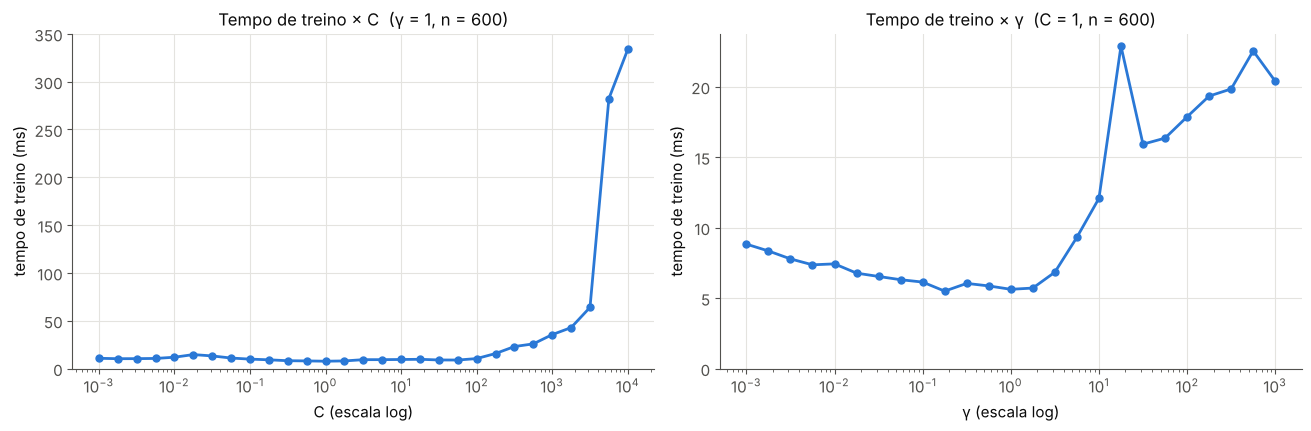

Tempo de treino: C=0,001 → 10.7 ms · C=1 → 7.7 ms · C=10⁴ → 333.7 ms


In [ ]:
X_tr, X_va, X_te, y_tr, y_va, y_te = DADOS["moons"]
t_C = [tempo_mediano(svm(kernel="rbf", C=c, gamma=1), X_tr, y_tr) for c in Cs]
t_g = [tempo_mediano(svm(kernel="rbf", C=1, gamma=g), X_tr, y_tr) for g in gammas]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
axes[0].plot(Cs, t_C, "o-", color=AZUL, ms=5)
axes[0].set(xscale="log", xlabel="C (escala log)", ylabel="tempo de treino (ms)", title="Tempo de treino × C  (γ = 1, n = 600)")
axes[1].plot(gammas, t_g, "o-", color=AZUL, ms=5)
axes[1].set(xscale="log", xlabel="γ (escala log)", ylabel="tempo de treino (ms)", title="Tempo de treino × γ  (C = 1, n = 600)")
for ax in axes:
    ax.set_ylim(bottom=0)
plt.show()
print(f"Tempo de treino: C=0,001 → {t_C[0]:.1f} ms · C=1 → {t_C[int(np.argmin(np.abs(Cs - 1)))]:.1f} ms · C=10⁴ → {t_C[-1]:.1f} ms")

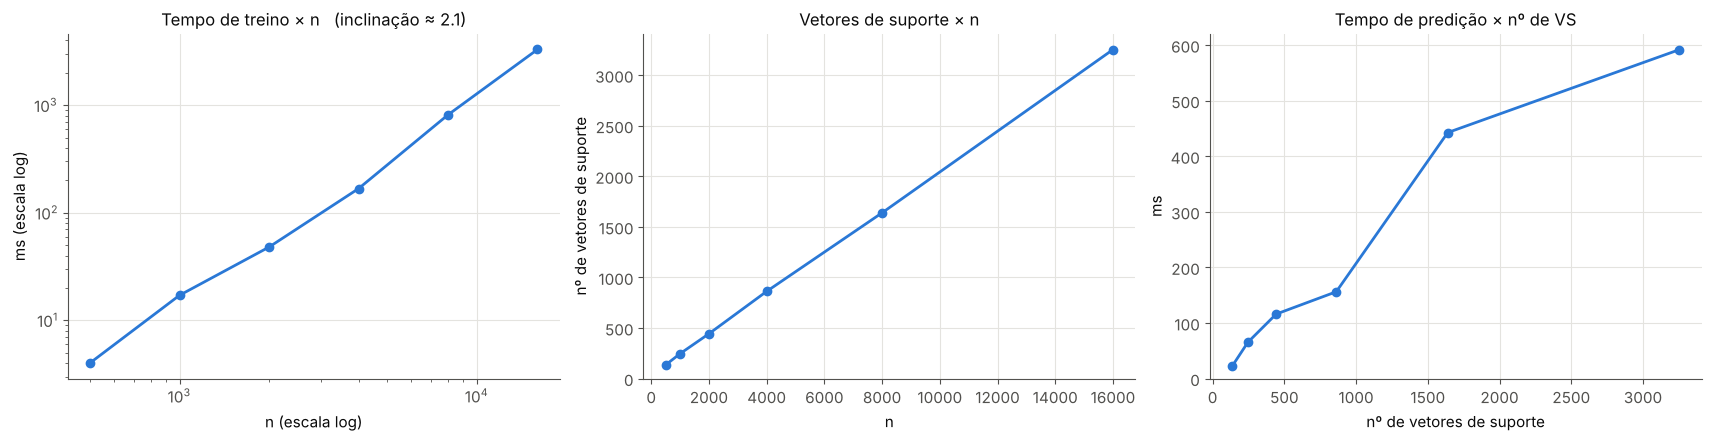

n,treino (ms),nº VS,predição de 5000 pontos (ms)
500,4.0,135,21.7
1000,17.1,246,65.3
2000,48.0,443,116.0
4000,167.6,862,156.2
8000,813.9,1639,442.6
16000,3298.3,3253,591.9


Tempo de treino ~ n^2.1 (ajuste em log-log nos maiores n) · VS ≈ 23% dos pontos em todos os tamanhos


In [ ]:
# escalabilidade: moons com n crescente, hiperparâmetros fixos (C = 1, γ = 1)
ns = [500, 1000, 2000, 4000, 8000, 16000]
linhas_n = []
for n in ns:
    Xn, yn = make_moons(n_samples=n, noise=0.30, random_state=SEED)
    m = svm(kernel="rbf", C=1, gamma=1)
    t_fit = tempo_mediano(m, Xn, yn, rep=1 if n >= 8000 else 3)
    X_novo, _ = make_moons(n_samples=5000, noise=0.30, random_state=SEED + 1)
    t_pred = tempo_predicao(m, X_novo)
    linhas_n.append({"n": n, "treino (ms)": t_fit, "nº VS": int(m[-1].n_support_.sum()),
                     "predição de 5000 pontos (ms)": t_pred})
tab_n = pd.DataFrame(linhas_n)
expoente = np.polyfit(np.log(tab_n["n"][2:]), np.log(tab_n["treino (ms)"][2:]), 1)[0]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), layout="constrained")
axes[0].loglog(tab_n["n"], tab_n["treino (ms)"], "o-", color=AZUL, ms=6)
axes[0].set(xlabel="n (escala log)", ylabel="ms (escala log)", title=f"Tempo de treino × n   (inclinação ≈ {expoente:.1f})")
axes[1].plot(tab_n["n"], tab_n["nº VS"], "o-", color=AZUL, ms=6)
axes[1].set(xlabel="n", ylabel="nº de vetores de suporte", title="Vetores de suporte × n")
axes[2].plot(tab_n["nº VS"], tab_n["predição de 5000 pontos (ms)"], "o-", color=AZUL, ms=6)
axes[2].set(xlabel="nº de vetores de suporte", ylabel="ms", title="Tempo de predição × nº de VS")
for ax in axes[1:]:
    ax.set_ylim(bottom=0)
plt.show()
display(tab_n.style.format({"treino (ms)": "{:.1f}", "predição de 5000 pontos (ms)": "{:.1f}"}).hide(axis="index"))
print(f"Tempo de treino ~ n^{expoente:.1f} (ajuste em log-log nos maiores n) · "
      f"VS ≈ {100 * (tab_n['nº VS'] / tab_n['n']).mean():.0f}% dos pontos em todos os tamanhos")


**Leitura dos resultados (tempo e complexidade)**

- **Tempo × $C$:** o treinamento ficou rápido (≈ 10 ms) para valores menores de $C$, mas aumentou bastante quando $C=10^4$ (25 a 45 vezes). Isso acontece porque valores altos de $C$ tornam a otimização mais difícil.

- **Tempo × $\gamma$:** o tempo variou pouco, mas aumentou cerca de 2 a 3 vezes para $\gamma$ elevado, quando mais pontos se tornaram vetores de suporte (VS).

- **Escalabilidade:** nos experimentos, dobrar a quantidade de dados aumentou o tempo de treinamento em aproximadamente 4 a 5 vezes. Isso mostra que a SVM com kernel pode ser computacionalmente cara para bases muito grandes.

- **Complexidade do modelo:** o número de vetores de suporte cresceu proporcionalmente à quantidade de dados (cerca de 20–25% dos exemplos). Quanto mais VS, maior o custo de predição.


## `Avaliação final no conjunto de teste`

Para cada conjunto: seleção de $C$ e $\gamma$ por validação cruzada em treino + validação (mesma grade 13 × 13 da seção 6), **retreino com todos os 800 pontos de desenvolvimento** e avaliação **uma única vez** nos 200 pontos de teste.

In [ ]:
linhas_f, finais = [], {}
for nome, (X_tr, X_va, X_te, y_tr, y_va, y_te) in DADOS.items():
    X_dev, y_dev = DEV[nome]
    busca, res, _ = (busca_moons, res_moons, None) if nome == "moons" else selecionar(X_dev, y_dev)
    c, g = busca.best_params_["svc__C"], busca.best_params_["svc__gamma"]
    final = svm(kernel="rbf", C=c, gamma=g)
    t_fit = tempo_mediano(final, X_dev, y_dev)
    pred = final.predict(X_te)
    t_pred = tempo_predicao(final, X_te)
    finais[nome] = (final, X_dev, y_dev, pred)
    n_vs = int(final[-1].n_support_.sum())
    linhas_f.append({"conjunto": nome, "C*": c, "γ*": g, "acc VC (dev)": busca.best_score_,
                     "acc teste": accuracy_score(y_te, pred), "F1 teste": f1_score(y_te, pred),
                     "nº VS": n_vs, "% VS": 100 * n_vs / len(y_dev), "treino (ms)": t_fit, "predição teste (ms)": t_pred})
tab_f = pd.DataFrame(linhas_f).set_index("conjunto")
display(tab_f.style.format({"C*": "{:.3g}", "γ*": "{:.3g}", "acc VC (dev)": "{:.3f}", "acc teste": "{:.3f}",
                            "F1 teste": "{:.3f}", "% VS": "{:.1f}", "treino (ms)": "{:.1f}", "predição teste (ms)": "{:.2f}"}))

,C*,γ*,acc VC (dev),acc teste,F1 teste,nº VS,% VS,treino (ms),predição teste (ms)
conjunto,,,,,,,,,
moons,0.316,3.16,0.912,0.935,0.934,284,35.5,14.6,3.70
circles,31.6,0.0316,0.980,0.985,0.985,129,16.1,9.1,1.04


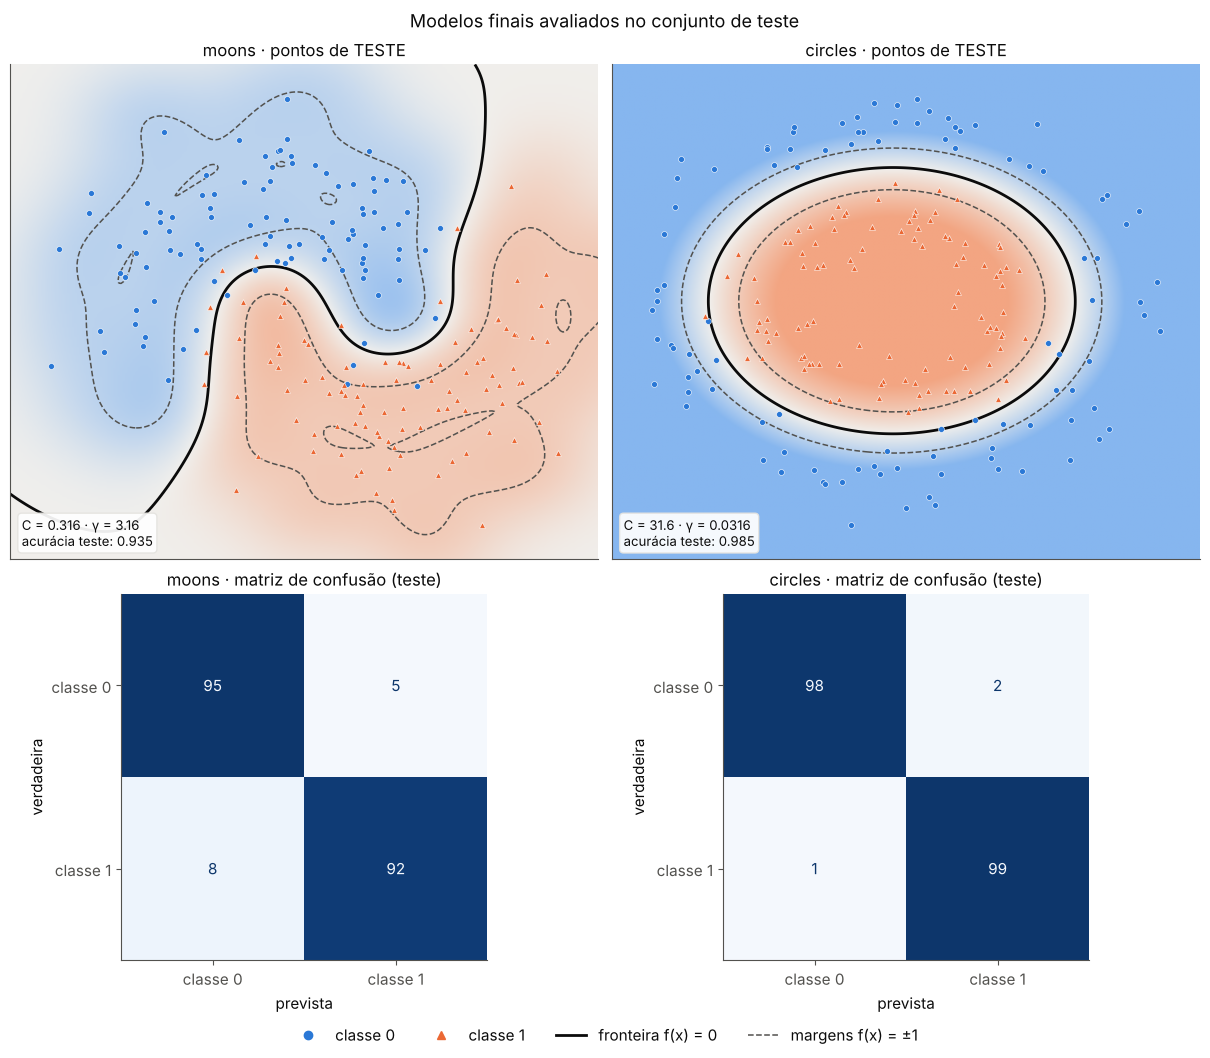

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10.5), layout="constrained", gridspec_kw={"height_ratios": [1.35, 1]})
for j, (nome, (final, X_dev, y_dev, pred)) in enumerate(finais.items()):
    X_te, y_te = DADOS[nome][2], DADOS[nome][5]
    lin = tab_f.loc[nome]
    plot_fronteira(final, X_te, y_te, axes[0, j], titulo=f"{nome} · pontos de TESTE",
                   info=f"C = {lin['C*']:.3g} · γ = {lin['γ*']:.3g}\nacurácia teste: {lin['acc teste']:.3f}")
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["classe 0", "classe 1"]).plot(
        ax=axes[1, j], cmap=CMAP_AZUL, colorbar=False)
    axes[1, j].set_title(f"{nome} · matriz de confusão (teste)"); axes[1, j].grid(False)
    axes[1, j].set_xlabel("prevista"); axes[1, j].set_ylabel("verdadeira")
legenda_fronteira(fig, vs=False)
fig.suptitle("Modelos finais avaliados no conjunto de teste")
plt.show()

**Leitura dos resultados (teste)**

- **moons:** $C^*\approx 0{,}32$, $\gamma^*\approx 3{,}2$ -> acurácia de teste 0,935 (F1 0,934), com 284 VS (35% dos pontos). O teste ficou um pouco acima da VC (0,912): com 200 pontos de teste, o erro-padrão da acurácia é ≈ 1,7 p.p., então a diferença está dentro da variação esperada. Os 13 erros se concentram na região onde as meias-luas se sobrepõem, que o ruído torna inevitável.
- **circles:** $C^*\approx 31{,}6$, $\gamma^*\approx 0{,}032$ -> acurácia de teste 0,985 (3 erros), com 129 VS (16%).
- **A seleção se adapta ao problema:** o $\gamma$ escolhido para o *circles* é 100× menor que o do *moons*. Um círculo é uma forma simples e suave, que não precisa de gaussianas estreitas; o $C$ maior compensa o $\gamma$ menor, o mesmo efeito de faixa diagonal do experimento 4.


## `Conclusões`

**Resposta a pergunta central**: como $C$ e $\gamma$ controlam a flexibilidade da fronteira


1. **$\gamma$ controla o alcance da influência dos vetores de suporte**, sendo o parâmetro que mais alterou a flexibilidade da fronteira nos experimentos. $\gamma$ pequeno -> fronteiras mais suaves e risco de subajuste; $\gamma$ grande -> fronteiras mais complexas, com "ilhas" ao redor dos pontos e risco de sobreajuste. No *moons*, com $C=1$ e $\gamma=1000$, a acurácia de treino chegou a 0,998, enquanto a de validação caiu para 0,705.

2. **$C$ controla o compromisso entre margem larga e penalização dos erros de treinamento.** $C$ pequeno -> margem larga, maior tolerância às violações e fronteira mais suave; $C$ grande -> margem mais estreita e maior esforço para acomodar os exemplos de treinamento. Com $\gamma=1$, a largura da margem no espaço de características diminuiu aproximadamente 1.400 vezes entre $C=10^{-3}$ e $C=10^4$.

3. **$C$ e $\gamma$ interagem:** os mapas de desempenho mostraram uma **faixa diagonal de boas combinações** no plano $\log C \times \log \gamma$, valores menores de $\gamma$ puderam ser compensados por valores maiores de $C$, e vice-versa. Entretanto, essa compensação apresentou limites nos extremos investigados. Por isso, os dois parâmetros devem ser **ajustados conjuntamente**, por busca em grade logarítmica com validação cruzada.

4. **A escolha do kernel influencia a capacidade de representar relações não lineares.** O kernel linear apresentou desempenho inferior nos dois conjuntos, especialmente no *circles*. Os kernels polinomial e RBF alcançaram resultados semelhantes, mas possuem representações diferentes. A RBF utiliza influências locais e não exige a escolha de um grau polinomial.

5. **A padronização é fortemente recomendada com kernel RBF**, pois ele depende das distâncias entre os exemplos. Sem ela, atributos de maior escala podem dominar o cálculo. No conjunto *Breast Cancer*, a acurácia média foi de 0,947 sem padronização, mesmo após otimização, contra 0,979 com padronização.

6. **O custo computacional depende do tamanho dos dados e dos hiperparâmetros.** Nos experimentos realizados, o tempo de treinamento cresceu aproximadamente com $n^2$. Valores elevados de $C$ também aumentaram o tempo de treinamento, enquanto o número de vetores de suporte influenciou diretamente o custo de predição.

**Limitações:**

- **Dados sintéticos em 2D:** os principais experimentos utilizaram conjuntos bidimensionais para permitir a visualização das fronteiras. Em alta dimensionalidade, a fronteira não pode ser visualizada diretamente, e a escala adequada de $\gamma$ depende das características dos dados.
- **Uma única semente e divisão inicial:** repetir os experimentos com diferentes sementes permitiria conclusões quantitativas mais robustas. No *moons*, o desvio da validação cruzada (≈ 0,03) foi maior que várias das diferenças comparadas.
- **Validação exploratória:** a validação hold-out utilizou apenas 200 exemplos, ficando sujeita a variações amostrais. Por isso, a seleção final utilizou validação cruzada.
- **Grade discreta:** a busca considerou valores específicos de $C$ e $\gamma$, de modo que outras combinações poderiam apresentar resultados superiores.
- **Tempos de execução:** dependem da máquina, da implementação (*libsvm*) e do cache; servem para comparar tendências, não valores absolutos.
- **Classes balanceadas:** utilizamos acurácia e F1. Problemas desbalanceados poderiam exigir métricas adicionais e estratégias como `class_weight`.

**Conclusão geral:** Os resultados demonstram que **a flexibilidade da SVM com kernel RBF não depende de um único hiperparâmetro, mas da interação entre $C$ e $\gamma$**. O melhor desempenho foi obtido ao equilibrar a capacidade de representar fronteiras não lineares com a necessidade de generalizar para dados não utilizados no treinamento.
